In [2]:
import numpy as np
import scipy
import trovolut as trv
from pathlib import Path

## 1. Fermi-Hubbard Hamiltonian

$$H = -t \sum_{\langle ij\rangle,\sigma} \left(c^\dagger_{i\sigma} c_{j\sigma} + \text{h.c.}\right) + U \sum_i n_{i,\uparrow} n_{i,\downarrow}$$

In [2]:
def get_hamiltonian():
    """Return Hamiltonian terms from a 1D Fermi-Hubbard model (cached)."""
    H = trv.qm.models.hubbard_1d(Lx=4, t_hop=1.0, U_onsite=4.0, boundary="open")
    return [t["coef"] * t["matrix"] for t in H.terms()]

hams = get_hamiltonian()
print(f"Model: 1D Fermi-Hubbard (4 sites, {int(np.log2(hams[0].shape[0]))} qubits, {len(hams)} terms)")

Model: 1D Fermi-Hubbard (4 sites, 8 qubits, 28 terms)


## 2. Define Constraints

We want the fastest program possible, but it must have a maximum error of 0.1.

In [3]:
time_constr = trv.eval.Time(max_seconds=1, hard=False, score_fn="exponential")
error_constr = trv.eval.Error(max_error=0.05, hard=True, hard_penalty=-100.0)

print(f"Constraint 1: {time_constr}\n             {time_constr.formula()}")
print(f"Constraint 2: {error_constr}\n             {error_constr.formula()}")

constraints = trv.eval.ConstraintSet([time_constr, error_constr])
print(f"\nCombined:    {constraints.formula()}")

Constraint 1: Time(1, w=1.0)
             score = exp(-time/1)
Constraint 2: Error(0.05, hard)
             score = 1 / (1 + error) · 𝟙(error ≤ 0.05) + (-100.0) · 𝟙(error > 0.05)

Combined:    Hard guards: (error satisfied)
  → If any violated: score = penalty (-100.0)
Soft score: (1.0·s_time) / 1.0


## 3. Configure Error Measurement

Define how error is computed - the setup and exact solution functions:

In [4]:
def setup():
    """Return inputs for the candidate function: (hams, t, psi0)."""
    hams = get_hamiltonian()
    psi0 = np.random.randn(hams[0].shape[0]) + 1j * np.random.randn(hams[0].shape[0])
    psi0 /= np.linalg.norm(psi0)
    return hams, 1.0, psi0

def exact_evolution(hams, t, psi0):
    """Compute exact evolution for reference."""
    return scipy.linalg.expm(-1j * sum(hams) * t) @ psi0

# Configure how error is measured
constraints.config_error(exact_fn=exact_evolution, setup_fn=setup).entry_point("run_dynamics")

ConstraintSet([Time(1, w=1.0), Error(0.05, hard)])

## 4. Generate Files with Workflow

**Note:** If you get an `OSError: could not get source code` error, restart the kernel and run all cells from the beginning. 

Pass `constraints` to auto-generate the evaluator:

In [5]:
Path("opt").mkdir(exist_ok=True)

# Initial program (what OpenEvolve will optimize)
def run_dynamics(hams, t, psi0):
    """First-order Trotter evolution."""
    n_steps, dt = 50, t / 50
    psi = psi0.copy()
    for _ in range(n_steps):
        for H in hams:
            if np.random.rand() < 0.9:
                psi = scipy.linalg.expm(-1j * H * dt) @ psi
    return psi

# Build workflow with constraints attached
workflow = trv.filemaker.Workflow(
    [trv.filemaker.EVO_START, run_dynamics, trv.filemaker.EVO_END],
    out_path="opt/initial_program.py",
    imports=["import scipy", "import numpy as np"],
    constraints=constraints,  # enables build_evaluator()
)

# Build both files
init_path = workflow.build()
evaluator_path = workflow.build_evaluator()

print(f"Initial:   {init_path}")
print(f"Evaluator: {evaluator_path}")

Initial:   opt/initial_program.py
Evaluator: opt/evaluator.py


## 5. Test Evaluator

In [6]:
# Load the generated evaluator
exec(open(evaluator_path).read())

result = evaluate(str(init_path))
print(f"Score: {result['combined_score']:.4f}, All satisfied: {result['all_satisfied']}")
for name, info in result['details'].items():
    print(f"  {name}: {info['value']:.4f} → score={info['score']:.4f}")

Score: -100.0000, All satisfied: False
  time: 2.2918 → score=0.1011
  error: 0.0994 → score=-100.0000


## 6. Run OpenEvolve

In [7]:
# Auto-generate prompt from constraints
print(constraints.generate_prompt())

You are optimizing quantum simulation code. Your objectives are:

**Hard requirements (MUST satisfy):**
- Simulation error MUST be below 0.05 (hard requirement).

**Optimization goals (weighted):**
- Prefer faster execution (target: <1s, weight: 1.0).


In [9]:
from tabnanny import verbose
import nest_asyncio
import os
nest_asyncio.apply()

from openevolve import run_evolution
from openevolve.config import Config, LLMModelConfig, PromptConfig

config = Config(checkpoint_interval=10)
config.prompt = PromptConfig(system_message=constraints.generate_prompt())

# Configure NVIDIA inference endpoint
config.llm.models = [
    LLMModelConfig(
        name="openai/openai/gpt-5.2",
        api_base="https://inference-api.nvidia.com/v1",
        api_key=os.getenv("NVIDIA_API_KEY"),  # or set directly: api_key="your_key_here"
        temperature=0.7,
        max_tokens=1024
    )
]

result = run_evolution(
    initial_program=str(init_path),
    evaluator=str(evaluator_path),
    iterations=100,
    config=config,
    output_dir="opt/evolution_results",
)

2026-01-27 19:16:38,634 - INFO - Logging to opt/evolution_results/logs/openevolve_20260127_191638.log
/Users/lmantilla/Desktop/Internship/trovolut/.venv/lib/python3.12/site-packages/openevolve/controller.py:96: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  random.seed(self.config.random_seed)
/Users/lmantilla/Desktop/Internship/trovolut/.venv/lib/python3.12/site-packages/openevolve/controller.py:97: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  np.random.seed(self.config.random_seed)
2026-01-27 19:16:38,635 - INFO - Set random seed to 42 for reproducibility
2026-01-27 19:16:38,829 - INFO - Initialized OpenAI LLM with model: openai/openai/gpt-5.2
2026-01-27 19:16:38,830 

In [3]:
# Create animated GIF showing code evolution through checkpoints
from trovolut.utils import create_diff_gif

create_diff_gif(
    run_dir=Path("opt"),
    width=1400,
    line_height=30,
    font_size=16,
    theme='dark',  # Use 'light' for light theme
    include_final_best=True
)

Found 10 checkpoints
Created frame for initial program
Created frame for checkpoint_10
Created frame for checkpoint_20
Created frame for checkpoint_30
Created frame for checkpoint_40
Created frame for checkpoint_50
Created frame for checkpoint_60
Created frame for checkpoint_70
Created frame for checkpoint_80
Created frame for checkpoint_90
Created frame for checkpoint_100
Created frame for final best program

GIF saved to opt/evolution_results/code_evolution_diff.gif
Total frames: 12
Duration per frame: 2000ms
Total duration: 24.0s


PosixPath('opt/evolution_results/code_evolution_diff.gif')

## 7. Analyze Evolution Results

Parse all checkpoints and visualize the evolution progress.

In [10]:
from trovolut.utils.parse import parse_all_checkpoints, extract_evolution_metrics

# Parse all checkpoints
checkpoints = parse_all_checkpoints("opt/evolution_results/checkpoints")
metrics = extract_evolution_metrics(checkpoints)

print(f"Loaded {len(checkpoints)} checkpoints")
print(f"Iterations: {metrics['iterations']}")
print(f"\nFinal metrics:")
print(f"  Combined score: {metrics['combined_scores'][-1]:.4f}")
print(f"  Time: {metrics['times'][-1]:.6f}s")
print(f"  Error: {metrics['errors'][-1]:.6e}")

2026-01-27 19:29:19,627 - INFO - Enabling RDKit 2025.09.3 jupyter extensions


Loaded 10 checkpoints
Iterations: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

Final metrics:
  Combined score: 0.9984
  Time: 0.001609s
  Error: -8.881784e-16


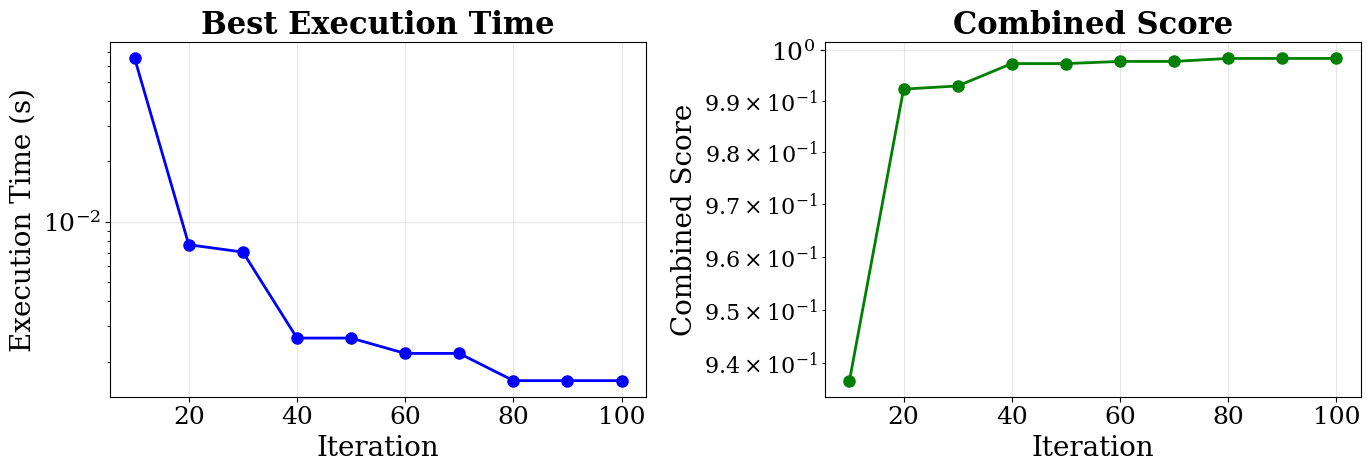


Evolution summary:
  Starting time: 0.065315s
  Final time: 0.001609s
  Speedup: 40.58x
  Final score: 0.9984


In [22]:
# Plot: Best execution time over iterations
import matplotlib.pyplot as plt

# Enable LaTeX font rendering
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 16

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Best time vs iterations
axes[0].plot(metrics['iterations'], metrics['times'], 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Iteration', fontsize=20)
axes[0].set_ylabel('Execution Time (s)', fontsize=20)
axes[0].set_title('Best Execution Time', fontsize=22, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')
axes[0].tick_params(axis='both', which='major', labelsize=18)

# 2. Combined score vs iterations
axes[1].plot(metrics['iterations'], metrics['combined_scores'], 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Iteration', fontsize=20)
axes[1].set_ylabel('Combined Score', fontsize=20)
axes[1].set_title('Combined Score', fontsize=22, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].set_yscale('log')
axes[1].tick_params(axis='both', which='major', labelsize=18)

plt.tight_layout()
plt.show()

print(f"\nEvolution summary:")
print(f"  Starting time: {metrics['times'][0]:.6f}s")
print(f"  Final time: {metrics['times'][-1]:.6f}s")
print(f"  Speedup: {metrics['times'][0] / metrics['times'][-1]:.2f}x")
print(f"  Final score: {metrics['combined_scores'][-1]:.4f}")

In [20]:
# Create MAP-Elites heatmap GIF showing evolution over time
from trovolut.utils.parse import extract_map_elites_grid
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path

# Extract grids for each checkpoint
grids = []
iterations_list = []
for i, cp in enumerate(checkpoints):
    cp_dir = f"opt/evolution_results/checkpoints/checkpoint_{cp['iteration']}"
    grid = extract_map_elites_grid(cp, cp_dir)
    grids.append(grid)
    iterations_list.append(cp['iteration'])

print(f"Created {len(grids)} MAP-Elites grids")

# Calculate global min/max for colorbar normalization
all_scores = np.concatenate([grid[~np.isnan(grid)] for grid in grids])
vmin = np.min(all_scores)
vmax = np.max(all_scores)
print(f"Score range: {vmin:.4f} to {vmax:.4f}")

# Enable LaTeX rendering
plt.rcParams['text.usetex'] = False  # Use mathtext instead for compatibility
plt.rcParams['font.family'] = 'serif'

# Create animation
fig, ax = plt.subplots(figsize=(10, 8))

# Create initial image and colorbar (only once) with normalized range
im = ax.imshow(grids[0], origin='lower', cmap='inferno', vmin=vmin, vmax=vmax, 
               interpolation='nearest', aspect='auto')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Combined Score', fontsize=20)
cbar.ax.tick_params(labelsize=20)

# Set axis labels and styling (only once)
ax.set_xlabel('Complexity Bin', fontsize=20)
ax.set_ylabel('Diversity Bin', fontsize=20)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.tick_params(axis='both', labelsize=20)
ax.grid(True, alpha=0.3, linewidth=0.5, color='white')

def update(frame):
    grid = grids[frame]
    iteration = iterations_list[frame]
    occupied_cells = int(np.sum(~np.isnan(grid)))
    
    # Update image data (don't clear the axis)
    im.set_data(grid)
    
    # Update title with proper newline
    title_text = f'MAP-Elites Grid - Iteration {iteration}\nOccupied Cells: {occupied_cells}/100'
    ax.set_title(title_text, fontsize=20, fontweight='bold')
    
    return im,

# Create animation
anim = FuncAnimation(fig, update, frames=len(grids), interval=500, blit=False, repeat=True)

# Save as GIF
output_path = "opt/evolution_results/map_elites_evolution.gif"
writer = PillowWriter(fps=2)
anim.save(output_path, writer=writer)
plt.close()

print(f"\nSaved MAP-Elites evolution GIF to: {output_path}")
print(f"Total frames: {len(grids)}")
print(f"Final coverage: {np.sum(~np.isnan(grids[-1])):.0f}/100 cells occupied")

2026-01-27 19:33:07,816 - INFO - Animation.save using <class 'matplotlib.animation.PillowWriter'>


Created 10 MAP-Elites grids
Score range: 0.9230 to 0.9984

Saved MAP-Elites evolution GIF to: opt/evolution_results/map_elites_evolution.gif
Total frames: 10
Final coverage: 26/100 cells occupied


In [18]:
# Detailed statistics and insights
print("="*60)
print(" Evolution Statistics Summary")
print("="*60)

print(f"\n{'Metric':<30} {'Initial':<15} {'Final':<15} {'Change':<15}")
print("-"*75)

# Time
initial_time = metrics['times'][0]
final_time = metrics['times'][-1]
speedup = initial_time / final_time
print(f"{'Execution Time (s)':<30} {initial_time:<15.6f} {final_time:<15.6f} {speedup:.2f}x faster")

# Error
initial_error = metrics['errors'][0]
final_error = metrics['errors'][-1]
error_improvement = (initial_error - final_error) / initial_error * 100
print(f"{'Simulation Error':<30} {initial_error:<15.6e} {final_error:<15.6e} {error_improvement:+.1f}%")

# Combined score
initial_score = metrics['combined_scores'][0]
final_score = metrics['combined_scores'][-1]
score_improvement = (final_score - initial_score) / max(abs(initial_score), 1e-10) * 100
print(f"{'Combined Score':<30} {initial_score:<15.4f} {final_score:<15.4f} {score_improvement:+.1f}%")

print("\n" + "="*60)
print(" Constraint Details")
print("="*60)

for constraint_name, constraint_data in metrics['scores_by_constraint'].items():
    print(f"\n{constraint_name.upper()}:")
    initial_val = constraint_data['values'][0]
    final_val = constraint_data['values'][-1]
    initial_score = constraint_data['scores'][0]
    final_score = constraint_data['scores'][-1]
    
    print(f"  Value:  {initial_val:.6e} → {final_val:.6e}")
    print(f"  Score:  {initial_score:.4f} → {final_score:.4f}")

print("\n" + "="*60)
print(f"\n✓ Analyzed {len(checkpoints)} checkpoints over {checkpoints[-1]['iteration']} iterations")
print(f"✓ Total programs evaluated: {checkpoints[-1]['num_programs']}")
print(f"✓ MAP-Elites coverage: {np.sum(~np.isnan(final_grid)):.0f}/100 cells")

 Evolution Statistics Summary

Metric                         Initial         Final           Change         
---------------------------------------------------------------------------
Execution Time (s)             0.065315        0.001609        40.58x faster
Simulation Error               1.897926e-04    -8.881784e-16   +100.0%
Combined Score                 0.9368          0.9984          +6.6%

 Constraint Details

TIME:
  Value:  6.531492e-02 → 1.609458e-03
  Score:  0.9368 → 0.9984

ERROR:
  Value:  1.897926e-04 → -8.881784e-16
  Score:  0.9998 → 1.0000


✓ Analyzed 10 checkpoints over 100 iterations
✓ Total programs evaluated: 69
✓ MAP-Elites coverage: 26/100 cells


In [15]:
# # Cleanup
# import shutil
# shutil.rmtree("opt", ignore_errors=True)